<a href="https://colab.research.google.com/github/zoeyye27-creator/MSSP607/blob/main/Assignments/Ye_Zoey_Week8_Participation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
%run '/content/drive/MyDrive/Google_Connection.py'

Current directory: /content/MSSP607


In [6]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import datetime as dt
import plotly.express as px

%matplotlib inline
pd.set_eng_float_format(accuracy=3, use_eng_prefix=True)
pd.set_option('display.float_format', lambda x: '%.0f' % x)

plt.rc('figure', figsize=(10, 6))
np.set_printoptions(precision=4, suppress=True)

In [10]:
sales = pd.read_csv(
    '/content/MSSP607/data/InternetSales.csv',
    parse_dates=['BirthDate', 'DateFirstPurchase', 'OrderDate', 'DueDate', 'ShipDate'],
    low_memory=False,
    index_col='ID',
    encoding='latin-1'
)

sales.head(5)

,CustomerKey,GeographyKey,City,CountryRegionCode,EnglishCountryRegionName,CustomerAlternateKey,Title,FirstName,MiddleName,LastName,...,ProductStandardCost,TotalProductCost,SalesAmount,TaxAmt,Freight,CarrierTrackingNumber,CustomerPONumber,OrderDate,DueDate,ShipDate
ID,,,,,,,,,,,,,,,,,,,,,
0,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,Yang,...,1912,1912,3400,272,85,NaN,NaN,2011-01-19,2011-01-31,2011-01-26
1,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,Yang,...,1266,1266,2320,186,58,NaN,NaN,2013-01-18,2013-01-30,2013-01-25
2,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,Yang,...,8,8,22,2,1,NaN,NaN,2013-01-18,2013-01-30,2013-01-25
3,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,Yang,...,1482,1482,2384,191,60,NaN,NaN,2013-05-03,2013-05-15,2013-05-10
4,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,Yang,...,11,11,29,2,1,NaN,NaN,2013-05-03,2013-05-15,2013-05-10


In [11]:
sales['OrderDate'] = pd.to_datetime(
    sales['OrderDate'],
    format='%m/%d/%Y'
)

sales['SalesAmount'] = pd.to_numeric(sales['SalesAmount'])

sales = sales.set_index('OrderDate').sort_index()

print('First date:', sales.index.min())
print('Last date:', sales.index.max())

display(sales['SalesAmount'].describe())

First date: 2010-12-29 00:00:00
Last date: 2014-01-28 00:00:00


,SalesAmount
count,60398
mean,486
std,928
min,2
25%,8
50%,30
75%,540
max,3578


In [12]:
product_summary = (
    sales.groupby('EnglishProductName')['SalesAmount']
    .agg(['sum', 'mean', 'median', 'std', 'count'])
    .rename(columns={
        'sum': 'TotalSales',
        'mean': 'AverageSales',
        'median': 'MedianSales',
        'std': 'SalesStd',
        'count': 'LineItems'
    })
    .sort_values('TotalSales', ascending=False)
)

display(product_summary.head(10))

top_product = product_summary.index[0]
top_sales = product_summary.iloc[0]['TotalSales']

print(f'Product with the highest historical sales: {top_product}')
print(f'Total sales: ${top_sales:,.2f}')
print(
    'If the historical sales mix continues, this product is a '
    'leading candidate to generate the most future revenue. '
    'Summary statistics alone cannot guarantee future sales.'
)

,TotalSales,AverageSales,MedianSales,SalesStd,LineItems
EnglishProductName,,,,,
"Mountain-200 Black, 46",1373470,2215,2295,115,620
"Mountain-200 Black, 42",1363142,2220,2295,113,614
"Mountain-200 Silver, 38",1339463,2247,2320,113,596
"Mountain-200 Silver, 46",1301100,2243,2320,115,580
"Mountain-200 Black, 38",1294866,2225,2295,111,582
"Mountain-200 Silver, 42",1257435,2245,2320,114,560
"Road-150 Red, 48",1205877,3578,3578,0,337
"Road-150 Red, 62",1202299,3578,3578,0,336
"Road-150 Red, 52",1080638,3578,3578,0,302


Product with the highest historical sales: Mountain-200 Black, 46
Total sales: $1,373,469.55
If the historical sales mix continues, this product is a leading candidate to generate the most future revenue. Summary statistics alone cannot guarantee future sales.


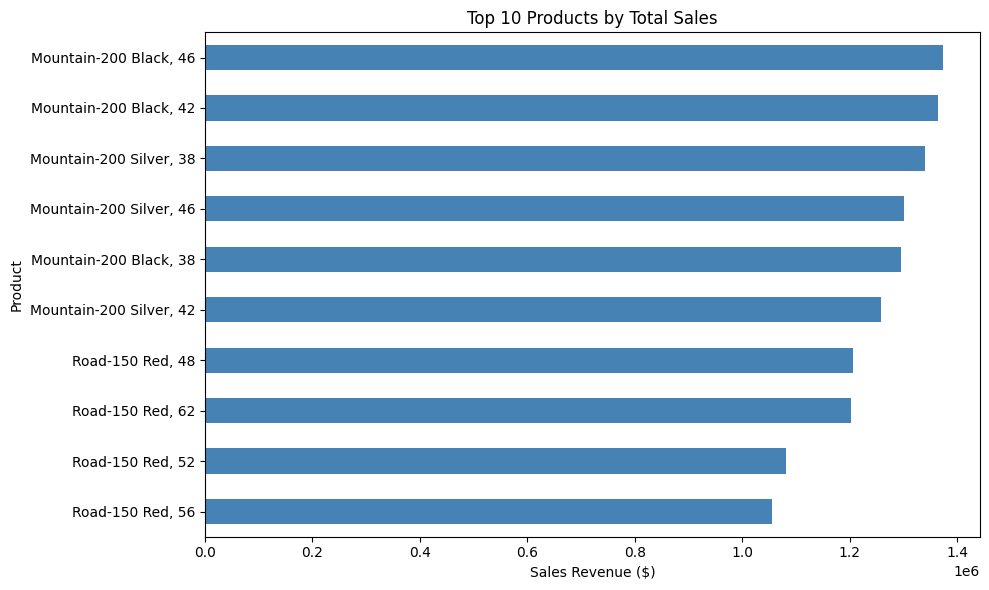

In [13]:
product_summary.head(10)['TotalSales'].sort_values().plot(
    kind='barh',
    color='steelblue'
)

plt.title('Top 10 Products by Total Sales')
plt.xlabel('Sales Revenue ($)')
plt.ylabel('Product')
plt.tight_layout()
plt.show()

In [14]:
monthly_sales = (
    sales.loc['2011-01-01':'2013-12-31', 'SalesAmount']
    .resample('MS')
    .sum()
)

annual_sales = monthly_sales.groupby(monthly_sales.index.year).sum()

print('Historical annual sales:')
display(annual_sales.to_frame(name='ActualSales'))

print('Monthly sales summary:')
display(monthly_sales.describe())

Historical annual sales:


,ActualSales
OrderDate,
2011,7075526
2012,5842485
2013,16351550


Monthly sales summary:


,SalesAmount
count,36
mean,813043
std,451341
min,358878
25%,500396
50%,608821
75%,1046994
max,1874360


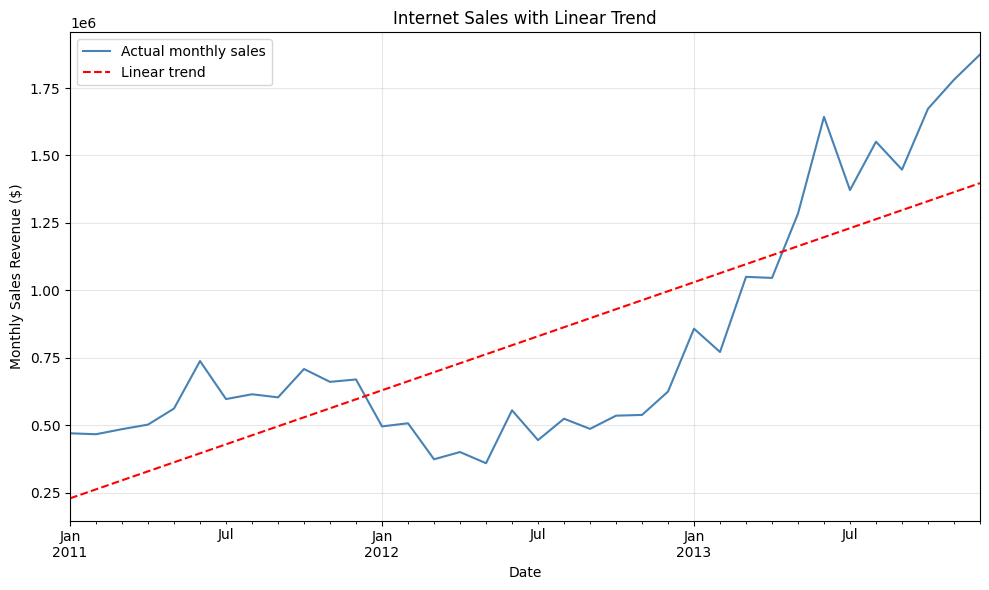

In [15]:
x = np.arange(len(monthly_sales))
y = monthly_sales.to_numpy()

slope, intercept = np.polyfit(x, y, 1)

trend = pd.Series(
    intercept + slope * x,
    index=monthly_sales.index,
    name='Trend'
)

monthly_sales.plot(label='Actual monthly sales', color='steelblue')
trend.plot(label='Linear trend', color='red', linestyle='--')

plt.title('Internet Sales with Linear Trend')
plt.xlabel('Date')
plt.ylabel('Monthly Sales Revenue ($)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [17]:
future_dates = pd.date_range(
    start=monthly_sales.index[-1] + pd.offsets.MonthBegin(1),
    periods=60,
    freq='MS'
)

future_x = np.arange(
    len(monthly_sales),
    len(monthly_sales) + 60
)

monthly_forecast = pd.Series(
    np.maximum(intercept + slope * future_x, 0),
    index=future_dates,
    name='ForecastSales'
)

annual_forecast = (
    monthly_forecast
    .groupby(monthly_forecast.index.year)
    .sum()
    .to_frame()
)

annual_forecast.index.name = 'Year'

display(annual_forecast)

print(
    'The forecast assumes the linear trend continues. '
    'It does not account for seasonality or changes in market conditions. '
    'Forecasting five years from three years of history is highly uncertain.'
)

,ForecastSales
Year,
2014,19373754
2015,24182371
2016,28990988
2017,33799604
2018,38608221


The forecast assumes the linear trend continues. It does not account for seasonality or changes in market conditions. Forecasting five years from three years of history is highly uncertain.


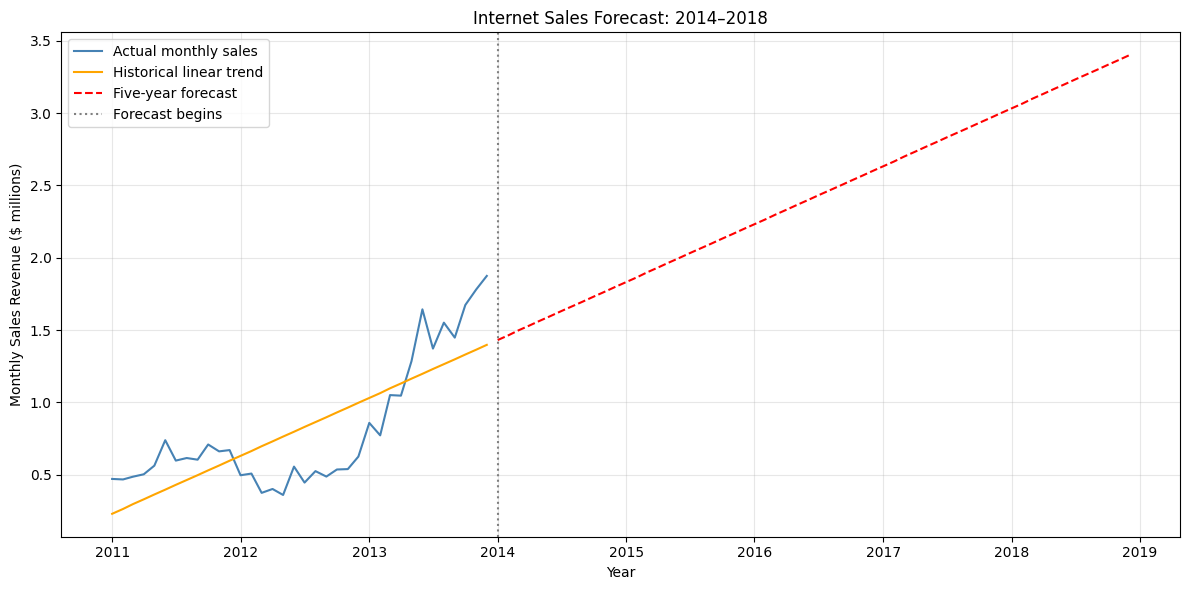

In [18]:

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    monthly_sales.index,
    monthly_sales / 1_000_000,
    label='Actual monthly sales',
    color='steelblue'
)

ax.plot(
    trend.index,
    trend / 1_000_000,
    label='Historical linear trend',
    color='orange'
)

ax.plot(
    monthly_forecast.index,
    monthly_forecast / 1_000_000,
    label='Five-year forecast',
    color='red',
    linestyle='--'
)

ax.axvline(
    future_dates[0],
    color='gray',
    linestyle=':',
    label='Forecast begins'
)

ax.set_title('Internet Sales Forecast: 2014–2018')
ax.set_xlabel('Year')
ax.set_ylabel('Monthly Sales Revenue ($ millions)')
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()